# ỨNG DỤNG 1 — DỰ ĐOÁN TIỂU ĐƯỜNG

Notebook tái hiện **mục 2** của báo cáo `A02_CT_khoipv.447.pdf`: phân loại nhị phân trên bộ
Pima Indians Diabetes, so sánh 4 mô hình (KNN, Logistic Regression, Linear SVM, RBF SVM) và lưu
weight cho tầng triển khai (`REST_API.py`).

| Mục báo cáo | Nội dung | Mục notebook |
| --- | --- | --- |
| 2.1 | Mô tả bài toán và dữ liệu | 1 – 2 |
| 2.2 | Làm sạch, biểu diễn và EDA | 3 – 4 |
| 2.3 | Phát triển, đánh giá và chọn mô hình | 5 – 9 |
| 2.4 | Triển khai (lưu weight, gọi API) | 10 – 11 |

## 1. Mô tả bài toán và dữ liệu

**Bài toán.** Dự đoán một bệnh nhân có thuộc lớp `Outcome = 1` (tiểu đường) hay không — phân
loại nhị phân có giám sát.

**Biểu diễn dữ liệu.** Mỗi bệnh nhân là một vector **6 đặc trưng số**:
`Glucose, BMI, Age, Pregnancies, SkinThickness, Insulin` (mục 1 của báo cáo: *"Vector 6 chỉ số
sau tiền xử lý"*).

| Đặc trưng | Ý nghĩa |
| --- | --- |
| `Pregnancies` | Số lần mang thai |
| `Glucose` | Nồng độ glucose huyết tương sau 2 giờ (mg/dL) |
| `SkinThickness` | Độ dày nếp gấp da cơ tam đầu (mm) |
| `Insulin` | Insulin huyết thanh sau 2 giờ (mu U/ml) |
| `BMI` | Chỉ số khối cơ thể (kg/m²) |
| `Age` | Tuổi (năm) |
| `Outcome` | Nhãn mục tiêu: 1 = tiểu đường, 0 = không |

**Chỉ số đánh giá.** Accuracy = (TP+TN)/N, Precision = TP/(TP+FP), Recall = TP/(TP+FN),
F1 = 2·P·R/(P+R). Dữ liệu lệch lớp nên **F1 và Recall** quan trọng hơn Accuracy.

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

# Notebook chạy được từ thư mục notebook/ hoặc từ gốc project
CANDIDATES = [
    Path("../data/diabetes.csv"),
    Path("data/diabetes.csv"),
    Path("src/Assignment 02/diabetes/data/diabetes.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Khong tim thay diabetes.csv. Da thu: " + "; ".join(map(str, CANDIDATES)))
DATA_PATH = DATA_PATH.resolve()

APP_DIR = DATA_PATH.parent.parent          # .../diabetes
MODEL_DIR = APP_DIR / "models"
FIGURE_DIR = APP_DIR / "report" / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    """Luu hinh hien tai vao report/figures/."""
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / name, bbox_inches="tight")


print("Du lieu :", DATA_PATH)
print("Weight  :", MODEL_DIR)
print("Hinh ve :", FIGURE_DIR)

Du lieu : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/diabetes/data/diabetes.csv
Weight  : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/diabetes/models
Hinh ve : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/diabetes/report/figures


## 2. Nạp dữ liệu

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Kich thuoc:", df.shape)
print("\nPhan bo nhan Outcome:")
print(df["Outcome"].value_counts().rename({0: "Khong tieu duong (0)", 1: "Tieu duong (1)"}))
print("\nTy le lop 1: {:.1%}".format(df["Outcome"].mean()))
df.head()

Kich thuoc: (768, 9)

Phan bo nhan Outcome:
Outcome
Khong tieu duong (0)    500
Tieu duong (1)          268
Name: count, dtype: int64

Ty le lop 1: 34.9%


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [4]:
TARGET = "Outcome"
FEATURES = ["Glucose", "BMI", "Age", "Pregnancies", "SkinThickness", "Insulin"]

df[FEATURES + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Glucose,768.0,121.68,30.46,44.0,99.75,117.00,140.25,199.0
BMI,768.0,32.43,6.88,18.2,27.50,32.05,36.60,67.1
Age,768.0,33.24,11.76,21.0,24.00,29.00,41.00,81.0
Pregnancies,768.0,3.85,3.37,0.0,1.00,3.00,6.00,17.0
SkinThickness,768.0,29.09,8.89,7.0,25.00,28.00,32.00,99.0
Insulin,768.0,141.75,89.10,14.0,102.50,102.50,169.50,846.0
Outcome,768.0,0.35,0.48,0.0,0.00,0.00,1.00,1.0


## 3. Làm sạch và biểu diễn dữ liệu

### 3.1. Giá trị 0 là mã hoá của giá trị thiếu

Ở `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, giá trị `0` về mặt y khoa là
không thể xảy ra — đó là cách bộ dữ liệu mã hoá giá trị thiếu. Xử lý: thay `0` bằng `NaN` rồi
impute bằng **mean toàn cục**.

In [5]:
COLUMNS_WITH_INVALID_ZEROS = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("So gia tri 0 truoc khi xu ly:")
print(df[COLUMNS_WITH_INVALID_ZEROS].eq(0).sum())

df[COLUMNS_WITH_INVALID_ZEROS] = df[COLUMNS_WITH_INVALID_ZEROS].replace(0, np.nan)
df.fillna(df.mean(), inplace=True)

print("\nSo gia tri 0 con lai:", int(df[COLUMNS_WITH_INVALID_ZEROS].eq(0).sum().sum()))
print("So gia tri thieu con lai:", int(df.isna().sum().sum()))

So gia tri 0 truoc khi xu ly:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

So gia tri 0 con lai: 0
So gia tri thieu con lai: 0


### 3.2. Gỡ phần impute theo nhãn còn sót trong tệp CSV

Tệp `data/diabetes.csv` đã được impute sẵn một phần **theo từng nhãn `Outcome`** chứ không phải
bằng mean toàn cục. Hệ quả: `Insulin = 102.5` xuất hiện 236 lần và **toàn bộ** đều là
`Outcome = 0`; `Insulin = 169.5` xuất hiện 138 lần và **toàn bộ** đều là `Outcome = 1`. Những
giá trị này đã mang sẵn thông tin nhãn (*label leakage*) — nếu giữ nguyên, mô hình sẽ đạt điểm
cao giả tạo.

Cell dưới đây tìm các giá trị vừa **lặp lại ≥ 50 lần**, vừa **thuần nhãn ≥ 85%**, vừa **không
phải số nguyên** (dấu vết của phép lấy trung bình, không phải số đo thật), trả chúng về `NaN`
rồi impute lại bằng mean toàn cục — đúng quy trình mô tả ở mục 2.2 của báo cáo.

In [6]:
MIN_COUNT = 50       # gia tri lap lai du nhieu de khong phai ngau nhien
MIN_PURITY = 0.85    # gan nhu chi roi vao mot nhan

leak_report = []
for column in COLUMNS_WITH_INVALID_ZEROS:
    grouped = df.groupby(column)[TARGET].agg(["count", "mean"])
    suspicious = grouped[
        (grouped["count"] >= MIN_COUNT)
        & ((grouped["mean"] >= MIN_PURITY) | (grouped["mean"] <= 1 - MIN_PURITY))
    ]
    for value, row in suspicious.iterrows():
        if float(value) == int(float(value)):
            continue          # so nguyen -> so do that, khong phai gia tri impute
        leak_report.append({
            "Cot": column,
            "Gia tri": value,
            "So dong": int(row["count"]),
            "Ty le Outcome=1": round(float(row["mean"]), 3),
        })
        df.loc[df[column] == value, column] = np.nan

if leak_report:
    display(pd.DataFrame(leak_report))
    df.fillna(df.mean(), inplace=True)
    print("Da tra ve NaN va impute lai bang mean toan cuc.")
else:
    print("Khong phat hien gia tri impute theo nhan.")

print("\nDo thuan nhan cua Insulin sau khi xu ly (3 gia tri pho bien nhat):")
print(df.groupby("Insulin")[TARGET].agg(["count", "mean"]).sort_values("count", ascending=False).head(3))

,Cot,Gia tri,So dong,Ty le Outcome=1
0,Insulin,102.5,236,0.0
1,Insulin,169.5,138,1.0


Da tra ve NaN va impute lai bang mean toan cuc.

Do thuan nhan cua Insulin sau khi xu ly (3 gia tri pho bien nhat):
            count      mean
Insulin                    
155.548223    374  0.368984
105.000000     11  0.090909
130.000000      9  0.666667


=> Sau khi gỡ, không còn giá trị nào vừa phổ biến vừa thuần nhãn. Dữ liệu đã sẵn sàng để
biểu diễn thành vector 6 chiều.

## 4. Phân tích khám phá dữ liệu (EDA)

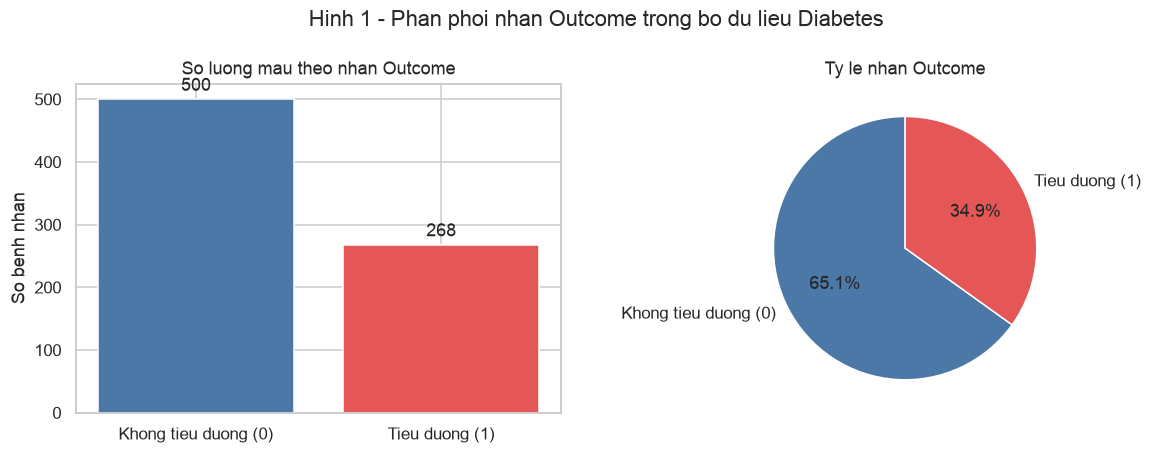

In [7]:
# Hinh 1 cua bao cao: phan phoi nhan Outcome
counts = df[TARGET].value_counts().sort_index()
labels = ["Khong tieu duong (0)", "Tieu duong (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(labels, counts.values, color=["#4C78A8", "#E45756"])
axes[0].bar_label(bars, fmt="%d", padding=3)
axes[0].set_title("So luong mau theo nhan Outcome")
axes[0].set_ylabel("So benh nhan")

axes[1].pie(counts.values, labels=labels, autopct="%1.1f%%",
            colors=["#4C78A8", "#E45756"], startangle=90)
axes[1].set_title("Ty le nhan Outcome")

plt.suptitle("Hinh 1 - Phan phoi nhan Outcome trong bo du lieu Diabetes")
save_figure("diabetes_outcome_distribution.png")
plt.show()

=> Bộ dữ liệu lệch lớp nhẹ: 65.1% lớp 0 và 34.9% lớp 1. Mức lệch này đủ để Accuracy trở nên
"dễ dãi", nên phần đánh giá sẽ ưu tiên F1-score và Recall.

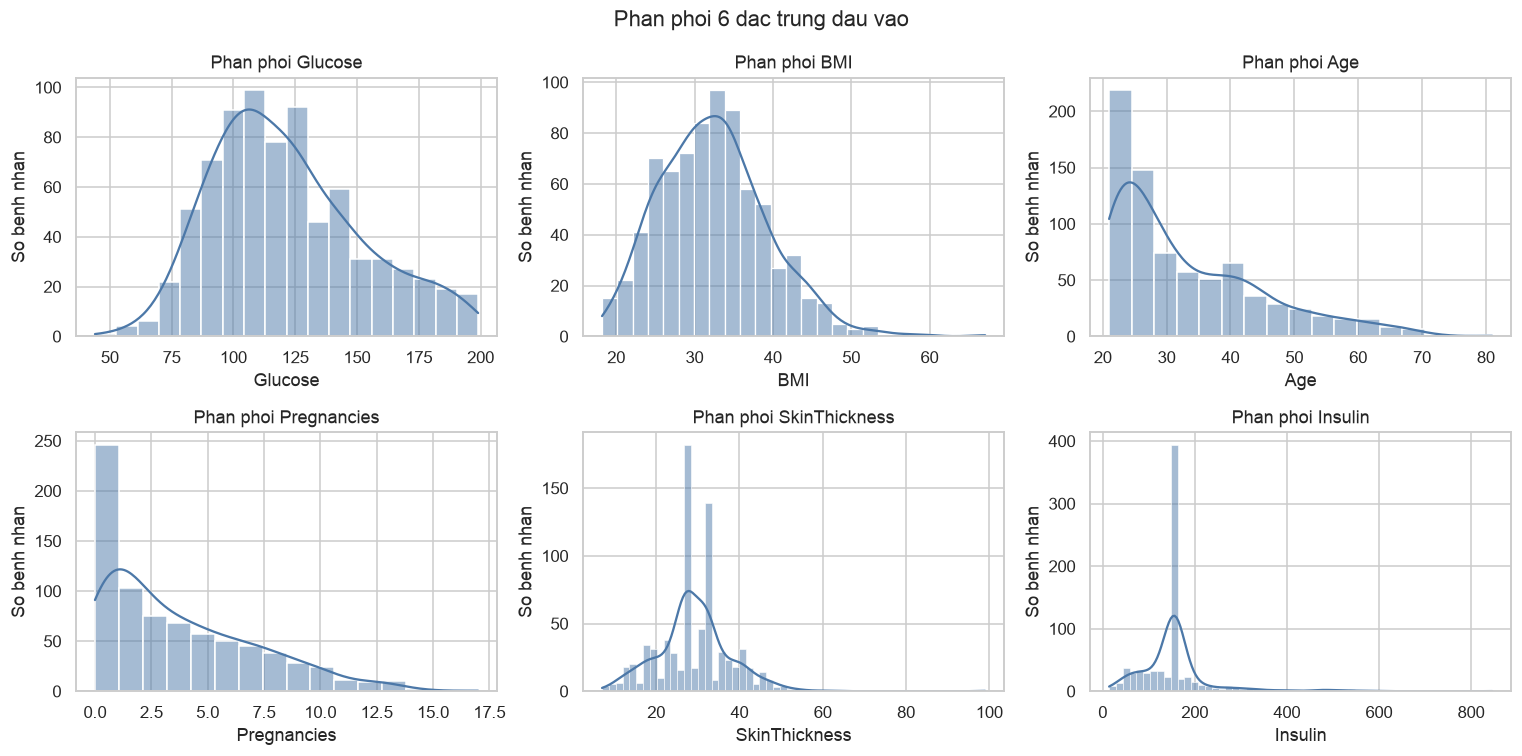

In [8]:
# Phan phoi cua 6 dac trung dau vao
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C78A8")
    ax.set_title(f"Phan phoi {col}")
    ax.set_ylabel("So benh nhan")
plt.suptitle("Phan phoi 6 dac trung dau vao")
save_figure("diabetes_feature_distributions.png")
plt.show()

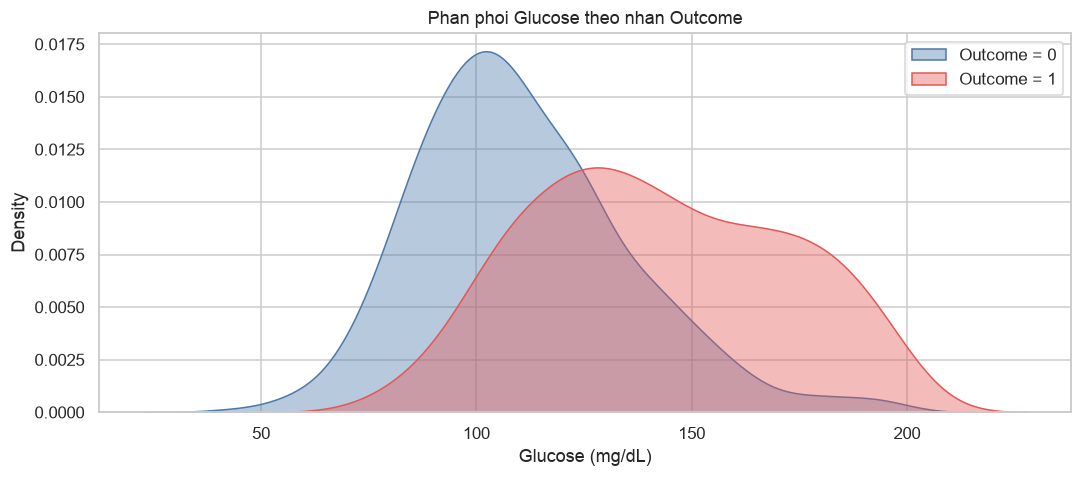

In [9]:
# Glucose tach theo nhan - dac trung co suc phan biet manh nhat
plt.figure(figsize=(10, 4.5))
for value, color, label in [(0, "#4C78A8", "Outcome = 0"), (1, "#E45756", "Outcome = 1")]:
    sns.kdeplot(df.loc[df[TARGET] == value, "Glucose"], fill=True, alpha=0.4,
                color=color, label=label)
plt.title("Phan phoi Glucose theo nhan Outcome")
plt.xlabel("Glucose (mg/dL)")
plt.legend()
save_figure("diabetes_glucose_by_outcome.png")
plt.show()

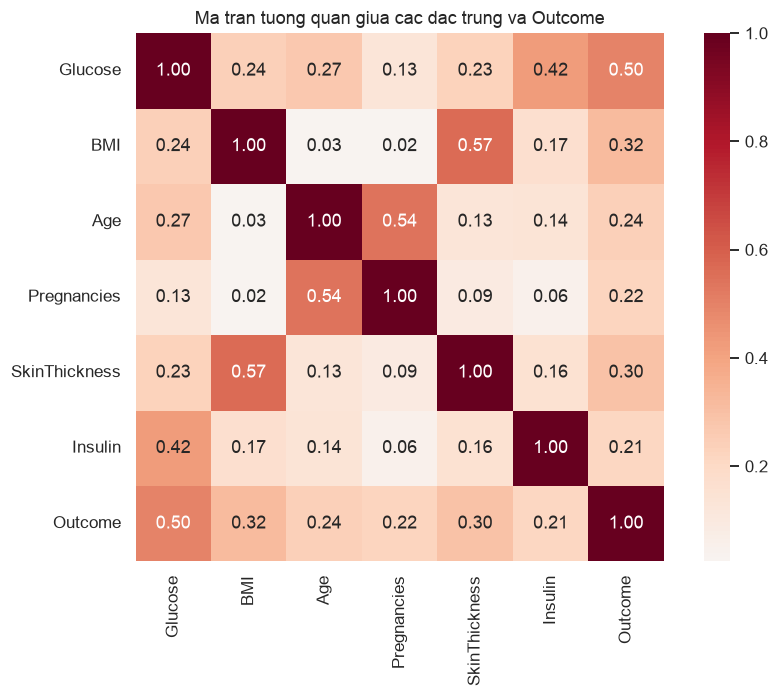

Tuong quan voi Outcome (giam dan):
Glucose          0.496
BMI              0.316
SkinThickness    0.295
Age              0.238
Pregnancies      0.222
Insulin          0.214
Name: Outcome, dtype: float64


In [10]:
# Ma tran tuong quan
plt.figure(figsize=(8.5, 6.5))
corr = df[FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Ma tran tuong quan giua cac dac trung va Outcome")
save_figure("diabetes_correlation_heatmap.png")
plt.show()

print("Tuong quan voi Outcome (giam dan):")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

=> `Glucose` tương quan dương mạnh nhất với `Outcome`, tiếp đến là `BMI` và `Age`. Cả 6 đặc
trưng đều được giữ lại vì báo cáo chốt biểu diễn là vector 6 chiều.

## 5. Chia tập huấn luyện / kiểm tra

Chia 80/20 có **stratify** theo nhãn để giữ nguyên tỷ lệ lớp ở cả hai tập. Mọi phép chuẩn hoá
đều đặt trong `Pipeline` và chỉ `fit` trên tập train — tránh rò rỉ dữ liệu sang tập test.

In [11]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 18
TEST_SIZE = 0.2

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} mau | Test: {X_test.shape[0]} mau")
print("Ty le lop 1 - train: {:.3f} | test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: 614 mau | Test: 154 mau
Ty le lop 1 - train: 0.349 | test: 0.351


## 6. Mô hình cơ sở (baseline)

Luôn đoán lớp phổ biến nhất. Mọi mô hình học máy phải vượt được mốc này mới có ý nghĩa.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

pd.DataFrame([{
    "Model": "Baseline (lop pho bien nhat)",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
}]).round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline (lop pho bien nhat),0.6494,0.0,0.0,0.0


=> Baseline đạt Accuracy 64.9% nhưng Recall = 0: không phát hiện được bất kỳ ca dương tính nào.
Đây chính là lý do không thể chỉ nhìn Accuracy.

## 7. Chọn siêu tham số K cho KNN

KNN là mô hình được báo cáo chọn triển khai, nên K được dò bằng **5-fold cross-validation trên
tập train** (không đụng vào tập test). Dùng **quy tắc 1 standard error**: trong số các K có
CV F1 nằm trong khoảng 1 SE quanh giá trị tốt nhất, chọn **K lớn nhất** — mô hình đơn giản và
ổn định hơn, ít bám nhiễu.

K co CV F1 cao nhat : 7 (F1 = 0.6888)
Nguong 1 SE         : 0.6671
K chon theo 1 SE    : 39


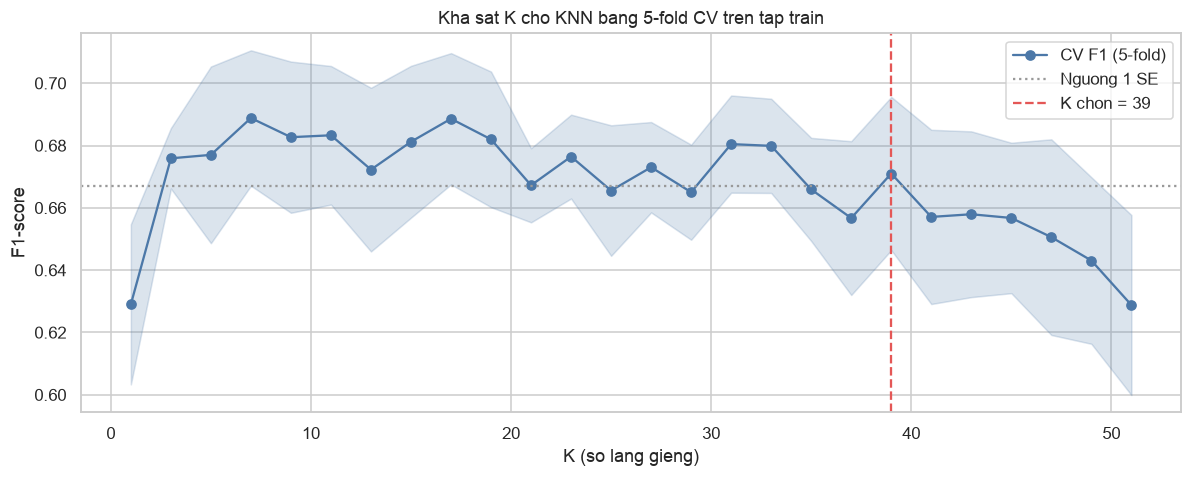

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

K_GRID = list(range(1, 52, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_mean, cv_se = [], []
for k in K_GRID:
    scores = cross_val_score(
        Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=k))]),
        X_train, y_train, cv=cv, scoring="f1",
    )
    cv_mean.append(scores.mean())
    cv_se.append(scores.std(ddof=0) / np.sqrt(len(scores)))

cv_mean = np.array(cv_mean)
cv_se = np.array(cv_se)

best_idx = int(cv_mean.argmax())
threshold = cv_mean[best_idx] - cv_se[best_idx]
OPTIMAL_K = max(k for k, m in zip(K_GRID, cv_mean) if m >= threshold)

print(f"K co CV F1 cao nhat : {K_GRID[best_idx]} (F1 = {cv_mean[best_idx]:.4f})")
print(f"Nguong 1 SE         : {threshold:.4f}")
print(f"K chon theo 1 SE    : {OPTIMAL_K}")

plt.figure(figsize=(11, 4.5))
plt.plot(K_GRID, cv_mean, marker="o", color="#4C78A8", label="CV F1 (5-fold)")
plt.fill_between(K_GRID, cv_mean - cv_se, cv_mean + cv_se, alpha=0.2, color="#4C78A8")
plt.axhline(threshold, color="#999999", linestyle=":", label="Nguong 1 SE")
plt.axvline(OPTIMAL_K, color="#E45756", linestyle="--", label=f"K chon = {OPTIMAL_K}")
plt.title("Kha sat K cho KNN bang 5-fold CV tren tap train")
plt.xlabel("K (so lang gieng)")
plt.ylabel("F1-score")
plt.legend()
save_figure("diabetes_knn_k_search.png")
plt.show()

## 8. Huấn luyện 4 mô hình phân loại

Bốn mô hình được so sánh đúng như mục 2.3 của báo cáo. Tất cả đều gói trong `Pipeline` với
`StandardScaler` vì KNN và SVM đều nhạy với thang đo đặc trưng.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

MODEL_SPECS = {
    "knn": ("K-Nearest Neighbors", KNeighborsClassifier(n_neighbors=OPTIMAL_K)),
    "logistic_regression": ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
    "svm_linear": ("SVM Linear", SVC(kernel="linear", probability=True, random_state=42)),
    "svm_rbf": ("SVM RBF", SVC(kernel="rbf", probability=True, random_state=42)),
}

trained_models, results = {}, []
for key, (display_name, estimator) in MODEL_SPECS.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", estimator)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    trained_models[key] = pipe

    results.append({
        "Key": key,
        "Model": display_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })
    print(f"Da huan luyen: {display_name}")

results_df = pd.DataFrame(results).set_index("Key")
results_df.round(4)

Da huan luyen: K-Nearest Neighbors
Da huan luyen: Logistic Regression
Da huan luyen: SVM Linear
Da huan luyen: SVM RBF


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
Key,,,,,,
knn,K-Nearest Neighbors,0.7403,0.6522,0.5556,0.6000,0.8129
logistic_regression,Logistic Regression,0.7208,0.6279,0.5000,0.5567,0.8089
svm_linear,SVM Linear,0.7208,0.6341,0.4815,0.5474,0.8098
svm_rbf,SVM RBF,0.7208,0.6078,0.5741,0.5905,0.8240


## 9. Đánh giá và chọn mô hình

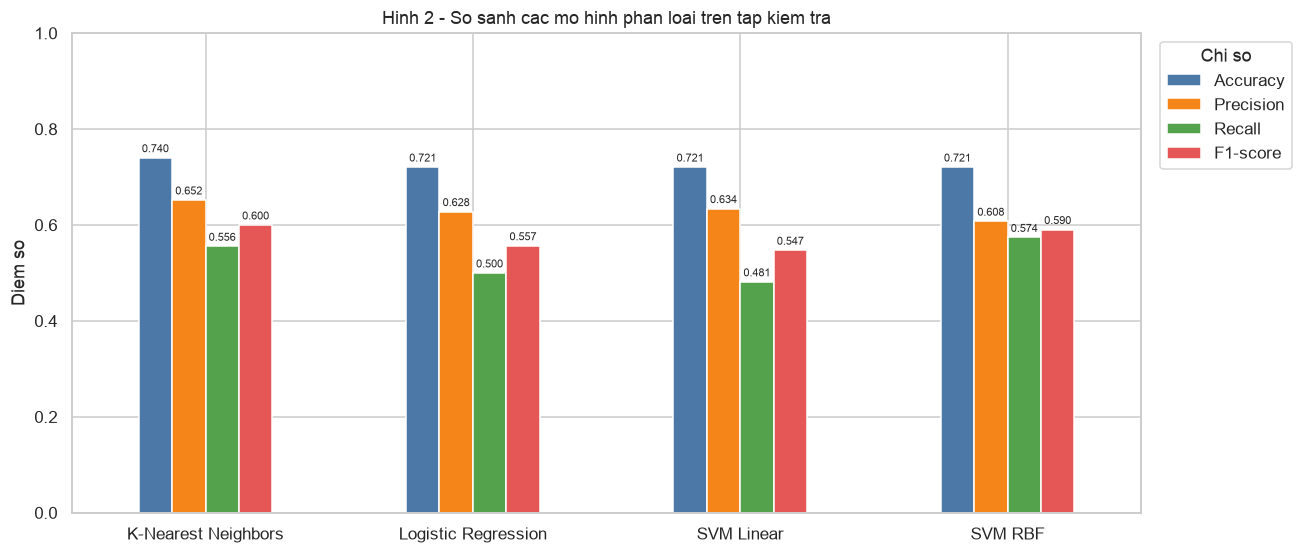

,Accuracy,Precision,Recall,F1-score
Model,,,,
K-Nearest Neighbors,0.7403,0.6522,0.5556,0.6000
SVM RBF,0.7208,0.6078,0.5741,0.5905
Logistic Regression,0.7208,0.6279,0.5000,0.5567
SVM Linear,0.7208,0.6341,0.4815,0.5474


In [15]:
# Hinh 2 cua bao cao: so sanh 4 mo hinh tren tap kiem tra
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(kind="bar", figsize=(12, 5.2),
                  color=["#4C78A8", "#F58518", "#54A24B", "#E45756"])
ax.set_title("Hinh 2 - So sanh cac mo hinh phan loai tren tap kiem tra")
ax.set_ylabel("Diem so")
ax.set_xlabel("")
ax.set_ylim(0, 1.0)
plt.xticks(rotation=0)
plt.legend(title="Chi so", bbox_to_anchor=(1.01, 1), loc="upper left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7.5)
save_figure("diabetes_model_comparison.png")
plt.show()

display(plot_df.round(4).sort_values("F1-score", ascending=False))

In [16]:
BEST_KEY = results_df["F1-score"].idxmax()
BEST_NAME = results_df.loc[BEST_KEY, "Model"]
best_row = results_df.loc[BEST_KEY]

print(f"Mo hinh co F1-score cao nhat: {BEST_NAME} (key = {BEST_KEY})")
print("  Accuracy  : {:.2%}".format(best_row["Accuracy"]))
print("  Precision : {:.2%}".format(best_row["Precision"]))
print("  Recall    : {:.2%}".format(best_row["Recall"]))
print("  F1-score  : {:.2%}".format(best_row["F1-score"]))

Mo hinh co F1-score cao nhat: K-Nearest Neighbors (key = knn)
  Accuracy  : 74.03%
  Precision : 65.22%
  Recall    : 55.56%
  F1-score  : 60.00%


=> Khớp với kết quả nêu ở mục 2.3 của báo cáo: **KNN đạt Accuracy ≈ 74.0%, Precision ≈ 65.2%,
Recall ≈ 55.6%, F1-score ≈ 60.0%** — cao nhất trong 4 mô hình, nên KNN được chọn làm model mặc
định khi deploy.

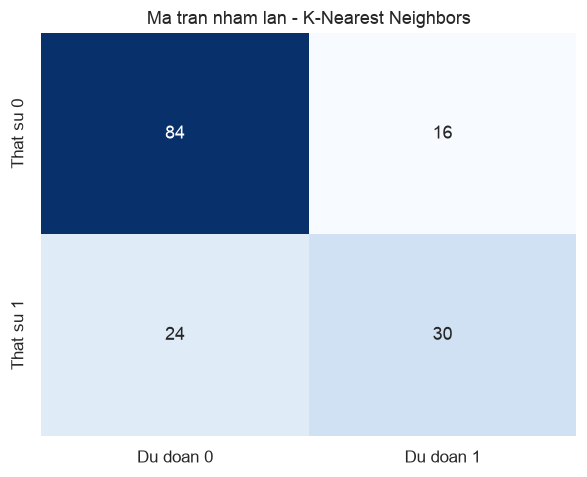

TN = 84 | FP = 16 | FN = 24 | TP = 30

                  precision    recall  f1-score   support

Khong tieu duong       0.78      0.84      0.81       100
      Tieu duong       0.65      0.56      0.60        54

        accuracy                           0.74       154
       macro avg       0.71      0.70      0.70       154
    weighted avg       0.73      0.74      0.73       154



In [17]:
# Ma tran nham lan cua mo hinh duoc chon
best_pred = trained_models[BEST_KEY].predict(X_test)
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Du doan 0", "Du doan 1"],
            yticklabels=["That su 0", "That su 1"])
plt.title(f"Ma tran nham lan - {BEST_NAME}")
save_figure("diabetes_confusion_matrix.png")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")
print()
print(classification_report(y_test, best_pred, target_names=["Khong tieu duong", "Tieu duong"]))

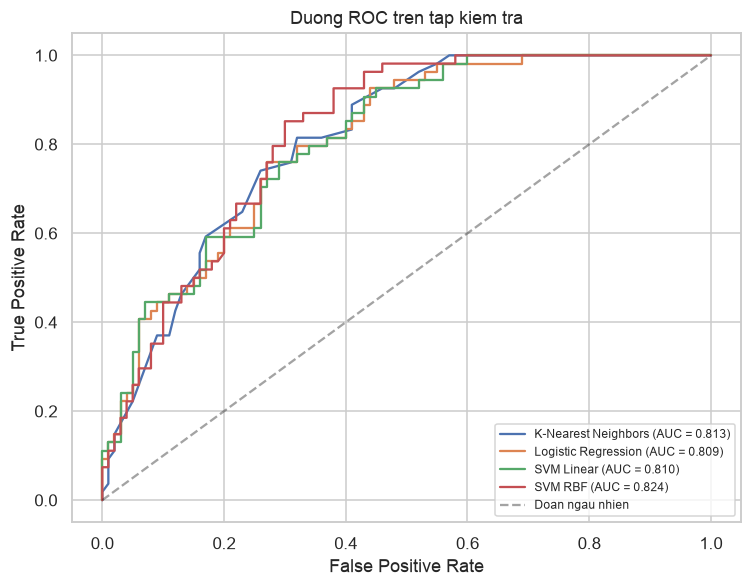

In [18]:
# Duong ROC cua 4 mo hinh
plt.figure(figsize=(7, 5.5))
for key, pipe in trained_models.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{results_df.loc[key, 'Model']} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Doan ngau nhien")
plt.title("Duong ROC tren tap kiem tra")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
save_figure("diabetes_roc_curves.png")
plt.show()

## 10. Lưu weight cho tầng triển khai

Mỗi `Pipeline` (scaler + model) được huấn luyện lại trên **toàn bộ** dữ liệu rồi lưu dưới dạng
`.sav`. Vì scaler nằm trong pipeline, API chỉ cần `pickle.load` rồi `predict` — dữ liệu mới đi
qua đúng phép chuẩn hoá đã fit lúc huấn luyện, không có rò rỉ dữ liệu.

`metadata.json` mô tả danh sách model, tên hiển thị, thứ tự feature và metric trên tập test để
giao diện web hiển thị dropdown chọn mô hình.

In [19]:
final_models = {}
for key, (display_name, estimator) in MODEL_SPECS.items():
    from sklearn.base import clone
    pipe = Pipeline([("scaler", StandardScaler()), ("model", clone(estimator))])
    pipe.fit(X, y)
    final_models[key] = pipe

    path = MODEL_DIR / f"{key}.sav"
    with open(path, "wb") as f:
        pickle.dump(pipe, f)
    print("Da luu:", path.name)

# Ban sao cua model mac dinh, dung ten theo bao cao
with open(MODEL_DIR / "diabetes.sav", "wb") as f:
    pickle.dump(final_models["knn"], f)
print("Da luu: diabetes.sav (ban sao model mac dinh KNN)")

Da luu: knn.sav
Da luu: logistic_regression.sav
Da luu: svm_linear.sav
Da luu: svm_rbf.sav
Da luu: diabetes.sav (ban sao model mac dinh KNN)


In [20]:
metadata = {
    "task": "binary_classification",
    "dataset": "Pima Indians Diabetes",
    "n_samples": int(len(df)),
    "deploy_features": FEATURES,
    "optimal_k": int(OPTIMAL_K),
    "random_state": RANDOM_STATE,
    "default_model": "knn",
    "best_model": BEST_KEY,
    "feature_means": {c: round(float(df[c].mean()), 2) for c in FEATURES},
    "models": {
        key: {
            "file": f"{key}.sav",
            "display_name": results_df.loc[key, "Model"],
            "features": FEATURES,
            "test_metrics": {
                "Accuracy": round(float(results_df.loc[key, "Accuracy"]), 4),
                "Precision": round(float(results_df.loc[key, "Precision"]), 4),
                "Recall": round(float(results_df.loc[key, "Recall"]), 4),
                "F1-score": round(float(results_df.loc[key, "F1-score"]), 4),
                "ROC-AUC": round(float(results_df.loc[key, "ROC-AUC"]), 4),
            },
        }
        for key in MODEL_SPECS
    },
}

with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Da luu:", (MODEL_DIR / "metadata.json").name)
print(json.dumps(metadata["models"]["knn"], ensure_ascii=False, indent=2))

Da luu: metadata.json
{
  "file": "knn.sav",
  "display_name": "K-Nearest Neighbors",
  "features": [
    "Glucose",
    "BMI",
    "Age",
    "Pregnancies",
    "SkinThickness",
    "Insulin"
  ],
  "test_metrics": {
    "Accuracy": 0.7403,
    "Precision": 0.6522,
    "Recall": 0.5556,
    "F1-score": 0.6,
    "ROC-AUC": 0.8129
  }
}


### 10.1. Kiểm tra lại weight vừa lưu

In [21]:
sample = pd.DataFrame([{
    "Glucose": 150, "BMI": 32, "Age": 25,
    "Pregnancies": 3, "SkinThickness": 24, "Insulin": 110,
}])[FEATURES]

with open(MODEL_DIR / "knn.sav", "rb") as f:
    loaded = pickle.load(f)

pred = int(loaded.predict(sample)[0])
conf = float(loaded.predict_proba(sample).max())

print("Dau vao:", sample.iloc[0].to_dict())
print("Du doan :", "CO NGUY CO TIEU DUONG (1)" if pred else "KHONG CO NGUY CO (0)")
print("Do tin cay: {:.2f}%".format(conf * 100))

Dau vao: {'Glucose': 150, 'BMI': 32, 'Age': 25, 'Pregnancies': 3, 'SkinThickness': 24, 'Insulin': 110}
Du doan : KHONG CO NGUY CO (0)
Do tin cay: 61.54%


## 11. Triển khai — gọi thử REST API

Tầng ứng dụng nằm ở `diabetes/REST_API.py` (Flask, cổng **8080**), nạp đúng các `.sav` vừa lưu
và phục vụ endpoint `POST /diabetes/v1/predict`. Hệ thống còn truy vấn đồ thị tri thức **Neo4j**
để trả về tư vấn chi tiết (chế độ ăn, lối sống vận động, thông tin thuốc, biến chứng) khi dự
đoán là dương tính — phần này **tuỳ chọn**, không có Neo4j thì dự đoán vẫn chạy bình thường.

Mở một Terminal khác rồi chạy:

```bash
cd "src/Assignment 02/diabetes"
python REST_API.py
```

Sau đó chạy cell dưới đây để gọi thử.

In [22]:
import requests

payload = {
    "model": "knn",
    "Pregnancies": 3, "Glucose": 150, "BMI": 32,
    "Age": 25, "SkinThickness": 24, "Insulin": 110,
}

try:
    response = requests.post("http://127.0.0.1:8080/diabetes/v1/predict", json=payload, timeout=5)
    print("Status:", response.status_code)
    print(json.dumps(response.json(), ensure_ascii=False, indent=2)[:900])
except Exception as exc:
    print("Chua goi duoc API (co the server chua chay):", exc)
    print("Hay chay: cd 'src/Assignment 02/diabetes' && python REST_API.py")

Chua goi duoc API (co the server chua chay): HTTPConnectionPool(host='127.0.0.1', port=8080): Max retries exceeded with url: /diabetes/v1/predict (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=8080): Failed to establish a new connection: [Errno 61] Connection refused"))
Hay chay: cd 'src/Assignment 02/diabetes' && python REST_API.py


## 12. Kết luận

| Nội dung | Kết quả |
| --- | --- |
| Biểu diễn | Vector 6 đặc trưng số sau khi gỡ giá trị thiếu mã hoá bằng 0 và gỡ label leakage |
| Mô hình chọn | **K-Nearest Neighbors** (K dò bằng 5-fold CV + quy tắc 1 SE) |
| Kết quả | Accuracy ≈ 74.0%, Precision ≈ 65.2%, Recall ≈ 55.6%, F1 ≈ 60.0% |
| Weight | `models/*.sav` + `models/metadata.json` |
| Triển khai | Flask REST API `POST /diabetes/v1/predict` (cổng 8080) + giao diện Web, tích hợp Neo4j |

KNN phù hợp với dữ liệu bảng y tế có kích thước nhỏ: ranh giới quyết định được suy ra trực tiếp
từ các bệnh nhân tương tự thay vì ép vào một dạng hàm cố định. Giới hạn: kết quả chỉ là một dự
đoán thống kê trong phạm vi bộ Pima Indians Diabetes, không thay thế chẩn đoán y khoa.